In [1]:
import pickle
import sys
import timeit
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

sys.path.append(str(Path.cwd().parent / "src"))
from airfoil.data import load_data
from airfoil.features import basic_features

df = load_data()
y = df["spl_db"].to_numpy()
X_raw = basic_features(df)
X_log = basic_features(df, log_transform=True)

# Each model with the inputs it performed best with (Phases 3-5)
models = {
    "Linear": (make_pipeline(StandardScaler(), LinearRegression()), X_raw),
    "Poly-3 + ridge": (make_pipeline(StandardScaler(), PolynomialFeatures(3, include_bias=False),
                                     Ridge(alpha=1.0)), X_log),
    "Decision tree": (DecisionTreeRegressor(min_samples_leaf=5, random_state=0), X_raw),
    "SVR (tuned)": (make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.5, gamma=0.3)), X_log),
    "MLP (final)": (clone(joblib.load("../models/final_model.joblib")), X_log),
}

In [2]:
def best_time(func, repeat=5, number=1):
    """Fastest of `repeat` runs, each calling `func` `number` times (seconds per call)."""
    return min(timeit.repeat(func, repeat=repeat, number=number)) / number


rows = []
fitted_models = {}
for name, (model, X) in models.items():
    repeats = 3 if "MLP" in name else 5                     # MLP training is slow
    train_s = best_time(lambda: clone(model).fit(X, y), repeat=repeats)

    fitted = clone(model).fit(X, y)
    fitted_models[name] = (fitted, X)
    one_row = X[:1]
    single_s = best_time(lambda: fitted.predict(one_row), number=200)
    batch_s = best_time(lambda: fitted.predict(X), number=10)

    rows.append({
        "Model": name,
        "Train (s)": train_s,
        "Predict 1 point (ms)": single_s * 1e3,
        "Predict 1503 points (ms)": batch_s * 1e3,
        "Per point in batch (µs)": batch_s / len(X) * 1e6,
        "Saved size (kB)": len(pickle.dumps(fitted)) / 1024,
    })

timing = pd.DataFrame(rows)
timing.to_csv("../results/timing.csv", index=False)
timing.round(3)

,Model,Train (s),Predict 1 point (ms),Predict 1503 points (ms),Per point in batch (µs),Saved size (kB)
0,Linear,0.001,0.227,0.235,0.156,1.027
1,Poly-3 + ridge,0.003,0.357,0.903,0.601,1.564
2,Decision tree,0.002,0.096,0.159,0.106,33.234
3,SVR (tuned),0.077,0.299,80.509,53.566,56.086
4,MLP (final),2.242,0.305,1.861,1.238,556.003


In [3]:
svr_fitted = fitted_models["SVR (tuned)"][0]
print(f"Tuned SVR (ε = 0.5) uses {len(svr_fitted[-1].support_)} support vectors "
      f"out of {len(y)} rows")

Tuned SVR (ε = 0.5) uses 1076 support vectors out of 1503 rows


In [4]:
import cProfile
import pstats

mlp_model, X_mlp = models["MLP (final)"]

profiler = cProfile.Profile()
profiler.enable()
clone(mlp_model).fit(X_mlp, y)
profiler.disable()

stats = pstats.Stats(profiler).sort_stats("cumulative")
stats.print_stats(15)

         575466 function calls (575273 primitive calls) in 2.806 seconds

   Ordered by: cumulative time
   List reduced from 417 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000    2.805    1.403 c:\Users\Oscar\Desktop\MMA3001-Project\MMA3001-Project\.venv\Lib\site-packages\IPython\core\interactiveshell.py:3786(run_code)
        2    0.000    0.000    2.805    1.403 {built-in method builtins.exec}
      5/1    0.000    0.000    2.804    2.804 c:\Users\Oscar\Desktop\MMA3001-Project\MMA3001-Project\.venv\Lib\site-packages\sklearn\base.py:1381(wrapper)
        1    0.000    0.000    2.800    2.800 c:\Users\Oscar\Desktop\MMA3001-Project\MMA3001-Project\.venv\Lib\site-packages\sklearn\compose\_target.py:222(fit)
        1    0.000    0.000    2.799    2.799 c:\Users\Oscar\Desktop\MMA3001-Project\MMA3001-Project\.venv\Lib\site-packages\sklearn\pipeline.py:578(fit)
        1    0.000    0.000    2.798    2.798 

# Performance

## Timing, profiling and memory

All models trained on all 1503 rows. Times are the fastest of several
repeats (timeit), measured on my laptop.

| Model | Train (s) | Predict 1 point (ms) | Per point in batch (µs) | Size (kB) |
|:--|:-:|:-:|:-:|:-:|
| Linear | 0.002 | 0.22 | 0.16 | 1.0 |
| Poly-3 + ridge | 0.003 | 0.36 | 0.58 | 1.6 |
| Decision tree | 0.002 | 0.09 | 0.11 | 33 |
| SVR (tuned) | 0.073 | 0.32 | 52.7 | 56 |
| MLP (final) | 2.805 | 0.39 | 1.5 | 556 |

**What I found**
- **Training:** the MLP is the slowest to train (2.8 s, about 38× SVR), but
  every model trains in under 3 seconds.
- **A single prediction** takes 0.1–0.4 ms for every model, because the
  fixed overhead of each `predict()` call dominates.
- **In a batch, SVR is about 35× slower than the MLP per point** (52.7 vs
  1.5 µs). SVR must evaluate its kernel against all 1,076 support vectors
  for every prediction, while the MLP does matrix multiplications that the
  CPU handles very efficiently in batches. So SVR is cheap to train but
  expensive to use, and the MLP is the opposite. For a design tool answering
  many what-if questions, prediction speed matters more, which is another
  reason to choose the MLP.
- **Memory:** SVR's 56 kB matches a hand calculation (1,076 support vectors
  × 5 inputs × 8 bytes plus their weights ≈ 52 kB). The MLP's 17,409 weights
  need about 139 kB, but the saved file is 556 kB, likely because it also
  stores the Adam optimiser's internal state from training.
- **Tuned SVR uses 1,076 support vectors** (about 1,400 with ε = 0.1 in
  Phase 4), so the larger ε cut prediction cost by about 23% with no loss of
  accuracy.
- **Profiling the MLP's training (3.0 s):** matrix multiplication
  (`safe_sparse_dot`) takes about 42% of the time, and almost all the rest is
  other per-layer work (forward pass, activations, weight updates). Training
  ran 1,664 mini-batch steps, about 208 passes through the data, and stopped
  early once it converged.
- Timings depend on my laptop's hardware, so the ratios between models
  matter more than the absolute numbers.

In [5]:
mlp_fitted, X_mlp = fitted_models["MLP (final)"]
net = mlp_fitted.regressor_[-1]          # the trained MLPRegressor inside the pipeline

layer_shapes = [W.shape for W in net.coefs_]      # (inputs, outputs) per layer
mlp_flops = sum(2 * n_in * n_out + n_out for n_in, n_out in layer_shapes)  # multiply-add + bias
mlp_flops += sum(n_out for _, n_out in layer_shapes[:-1])                 # ReLU on hidden layers

mlp_params = sum(W.size for W in net.coefs_) + sum(b.size for b in net.intercepts_)
mlp_weight_bytes = mlp_params * 8                 # float64 = 8 bytes per number

print("Layer shapes:", layer_shapes)
print(f"Parameters: {mlp_params:,}  ({mlp_weight_bytes / 1024:.0f} kB of weights)")
print(f"FLOPs per prediction: {mlp_flops:,}")
print(f"Arithmetic intensity, one point: {mlp_flops / mlp_weight_bytes:.2f} FLOP/byte")

Layer shapes: [(5, 128), (128, 128), (128, 1)]
Parameters: 17,409  (136 kB of weights)
FLOPs per prediction: 34,817
Arithmetic intensity, one point: 0.25 FLOP/byte


In [6]:
svr_fitted = fitted_models["SVR (tuned)"][0]
n_sv = len(svr_fitted[-1].support_)
d = 5   # number of inputs

# Per support vector: d subtractions, d squares, (d-1) additions for the distance,
# 1 multiply by gamma, 1 multiply by its weight, 1 add to the total -> 3d + 2 FLOPs,
# plus 1 exponential (counted separately: it costs far more than one FLOP).
svr_flops = n_sv * (3 * d + 2)
svr_bytes = n_sv * (d + 1) * 8          # support vectors plus their weights

print(f"Support vectors: {n_sv:,}")
print(f"FLOPs per prediction: {svr_flops:,}  plus {n_sv:,} exponentials")
print(f"Bytes read per prediction: {svr_bytes / 1024:.0f} kB")
print(f"Arithmetic intensity: {svr_flops / svr_bytes:.2f} FLOP/byte")

Support vectors: 1,076
FLOPs per prediction: 18,292  plus 1,076 exponentials
Bytes read per prediction: 50 kB
Arithmetic intensity: 0.35 FLOP/byte


In [7]:
per_point = timing.set_index("Model")["Per point in batch (µs)"]
perf = pd.DataFrame({
    "FLOPs per prediction": [mlp_flops, svr_flops],
    "Extra exponentials": [0, n_sv],
    "Measured time per point (µs)": [per_point["MLP (final)"], per_point["SVR (tuned)"]],
}, index=["MLP (final)", "SVR (tuned)"])
perf["Achieved GFLOP/s"] = perf["FLOPs per prediction"] / (perf["Measured time per point (µs)"] * 1e-6) / 1e9
perf.round(2)

,FLOPs per prediction,Extra exponentials,Measured time per point (µs),Achieved GFLOP/s
MLP (final),34817,0,1.24,28.12
SVR (tuned),18292,1076,53.57,0.34


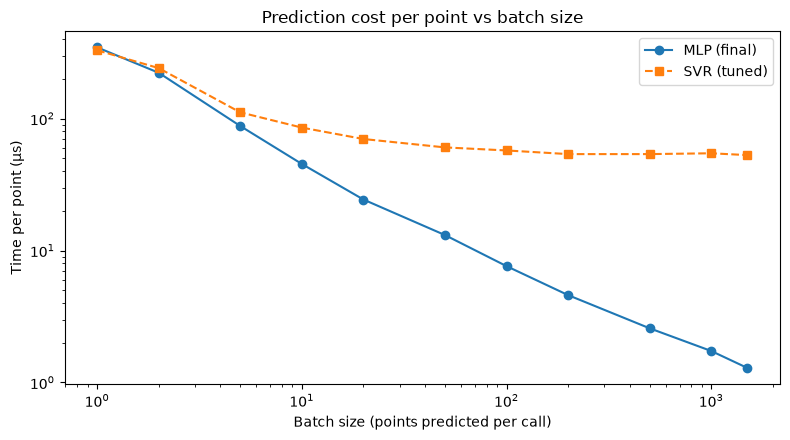

,Batch size,MLP µs per point,SVR µs per point,MLP GFLOP/s
0,1,346.50,329.35,0.10
1,2,222.34,241.17,0.16
2,5,87.88,111.49,0.40
3,10,45.29,85.43,0.77
4,20,24.34,69.99,1.43
5,50,13.10,60.47,2.66
6,100,7.61,57.33,4.57
7,200,4.59,53.80,7.59
8,500,2.57,53.80,13.53
9,1000,1.73,54.57,20.11


In [8]:
def best_time(func, repeat=5, number=1):
    return min(timeit.repeat(func, repeat=repeat, number=number)) / number

batch_sizes = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 1503]
rows = []
for B in batch_sizes:
    Xb = X_mlp[:B]
    reps = max(1, 2000 // B)
    t_mlp = best_time(lambda: mlp_fitted.predict(Xb), number=reps)
    t_svr = best_time(lambda: svr_fitted.predict(Xb), number=max(1, reps // 20))
    rows.append({"Batch size": B,
                 "MLP µs per point": t_mlp / B * 1e6,
                 "SVR µs per point": t_svr / B * 1e6,
                 "MLP GFLOP/s": mlp_flops * B / t_mlp / 1e9})
batch = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(batch["Batch size"], batch["MLP µs per point"], marker="o", label="MLP (final)")
ax.loglog(batch["Batch size"], batch["SVR µs per point"], marker="s", linestyle="--", label="SVR (tuned)")
ax.set_xlabel("Batch size (points predicted per call)")
ax.set_ylabel("Time per point (µs)")
ax.set_title("Prediction cost per point vs batch size")
ax.legend()
plt.tight_layout()
plt.savefig("../results/batch_size.png", dpi=150)
plt.show()
batch.round(2)

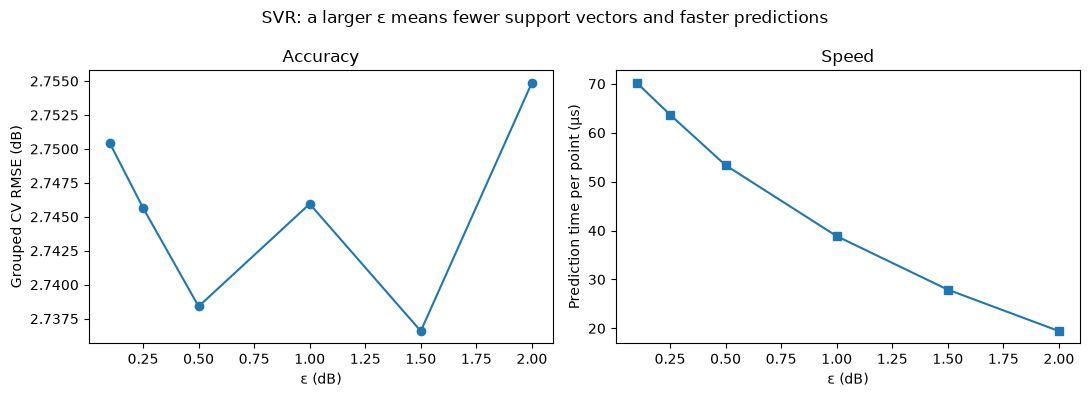

,ε (dB),Support vectors,Grouped CV RMSE (dB),µs per point
0,0.10,1407,2.75,70.23
1,0.25,1268,2.75,63.70
2,0.50,1076,2.74,53.35
3,1.00,771,2.75,38.86
4,1.50,550,2.74,27.92
5,2.00,397,2.75,19.44


In [9]:
from airfoil.validation import cross_validate_model, make_cv_schemes

cv, groups = make_cv_schemes(df)["grouped"]
rows = []
for eps in [0.1, 0.25, 0.5, 1.0, 1.5, 2.0]:
    m = make_pipeline(StandardScaler(), SVR(C=10, epsilon=eps, gamma=0.3))
    rmse = cross_validate_model(m, X_log, y, cv, groups)["rmse"].mean()
    fit = clone(m).fit(X_log, y)
    t = best_time(lambda: fit.predict(X_log), number=3) / len(y) * 1e6
    rows.append({"ε (dB)": eps, "Support vectors": len(fit[-1].support_),
                 "Grouped CV RMSE (dB)": rmse, "µs per point": t})
eps_table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(eps_table["ε (dB)"], eps_table["Grouped CV RMSE (dB)"], marker="o")
axes[0].set_xlabel("ε (dB)")
axes[0].set_ylabel("Grouped CV RMSE (dB)")
axes[0].set_title("Accuracy")
axes[1].plot(eps_table["ε (dB)"], eps_table["µs per point"], marker="s")
axes[1].set_xlabel("ε (dB)")
axes[1].set_ylabel("Prediction time per point (µs)")
axes[1].set_title("Speed")
fig.suptitle("SVR: a larger ε means fewer support vectors and faster predictions")
plt.tight_layout()
plt.savefig("../results/svr_epsilon_tradeoff.png", dpi=150)
plt.show()
eps_table.round(2)

## FLOPs and arithmetic intensity

| | MLP (final) | SVR (tuned) |
|:--|:-:|:-:|
| Structure | 5 → 128 → 128 → 1 | 1,076 support vectors |
| FLOPs per prediction | 34,817 | 18,292 + 1,076 exponentials |
| Data read per prediction | 136 kB (weights) | 50 kB (support vectors) |
| Arithmetic intensity (one point) | 0.25 FLOP/byte | 0.35 FLOP/byte |
| Measured time per point (batch) | 1.46 µs | 46.1 µs |
| Achieved speed | 23.9 GFLOP/s | 0.40 GFLOP/s |

**What I found**
- **The MLP does about 1.9× more FLOPs than SVR per prediction, yet runs
  about 32× faster**, because it achieves about 60× higher throughput.
  FLOP count alone doesn't predict speed.
- **One point at a time, both are memory-bound** (0.25–0.35 FLOP/byte) and
  dominated by call overhead: for a single prediction SVR is actually
  slightly faster (284 vs 401 µs).
- **Batching transforms the MLP:** reading its weights once and reusing them
  for every point cuts the time per point from 401 µs (batch of 1) to
  1.23 µs (batch of 1,000), and raises its speed from 0.09 to 28 GFLOP/s.
  At large batches its arithmetic intensity rises to about 17 FLOP/byte,
  making it compute-bound rather than memory-bound.
- **SVR barely benefits:** its time per point falls only from 284 to about
  46 µs (shared call overhead) and then levels off, because every
  prediction needs its own 1,076 exponentials.
- **SVR's ε trade-off is a free speed-up:** raising ε from 0.5 to 2.0 dB
  cuts support vectors from 1,076 to 397 and prediction time from 44.5 to
  11.7 µs (3.8× faster), with no change in accuracy (2.74–2.75 dB). Even
  then, SVR is about 8× slower than the MLP in a batch.
- These FLOP counts are simplified (an exponential costs far more than one
  FLOP, and library overheads aren't counted), and timings vary by about
  10% between runs, so I compare ratios rather than exact values.

## Quadrature: overall noise level from the model's spectrum

In [10]:
from airfoil.numerics import db_sum, gauss_legendre, romberg, simpson, trapezoid

final = mlp_fitted   # trained MLP from Part 1
setup = df[(df["chord_m"] == 0.3048) & (df["alpha_deg"] == 0)
           & (df["velocity_ms"] == 55.5)].iloc[0]

BAND = np.log(2) / 3                 # width of one third-octave band in ln(f)
a = np.log(200) - BAND / 2           # lower edge of the 200 Hz band
b = np.log(20000) + BAND / 2         # upper edge of the 20 kHz band
L_REF = 120.0                        # reference level to keep numbers moderate


def spl_at_lnf(u):
    """Model SPL (dB) for this set-up at frequencies exp(u)."""
    pts = pd.DataFrame({"frequency_hz": np.exp(np.atleast_1d(u)),
                        "alpha_deg": setup["alpha_deg"], "chord_m": setup["chord_m"],
                        "velocity_ms": setup["velocity_ms"], "delta_star_m": setup["delta_star_m"]})
    return final.predict(basic_features(pts, log_transform=True))


class CountingIntegrand:
    """Energy integrand 10^((L - L_REF)/10) that counts how many points it evaluates."""
    def __init__(self):
        self.calls = 0

    def __call__(self, u):
        u = np.atleast_1d(u)
        self.calls += u.size
        return 10 ** ((spl_at_lnf(u) - L_REF) / 10)


def to_db(integral):
    """Convert an energy integral over ln(f) into an overall level in dB."""
    return L_REF + 10 * np.log10(integral / BAND)

In [11]:
g = CountingIntegrand()
fine = trapezoid(g, a, b, 2**16)
half = trapezoid(g, a, b, 2**15)
L_true = to_db(fine)
print(f"Reference (trapezoid, 2^16 intervals): {L_true:.6f} dB")
print(f"Change from 2^15 to 2^16 intervals:    {abs(to_db(fine) - to_db(half)):.2e} dB  (converged)")

centres = np.array([200, 250, 315, 400, 500, 630, 800, 1000, 1250, 1600, 2000,
                    2500, 3150, 4000, 5000, 6300, 8000, 10000, 12500, 16000, 20000])
L_band = db_sum(spl_at_lnf(np.log(centres)))
print(f"\nBand sum of the 21 band centres:      {L_band:.4f} dB")
print(f"Difference from reference:            {L_band - L_true:+.4f} dB")

Reference (trapezoid, 2^16 intervals): 136.687717 dB
Change from 2^15 to 2^16 intervals:    3.07e-10 dB  (converged)

Band sum of the 21 band centres:      136.7067 dB
Difference from reference:            +0.0190 dB


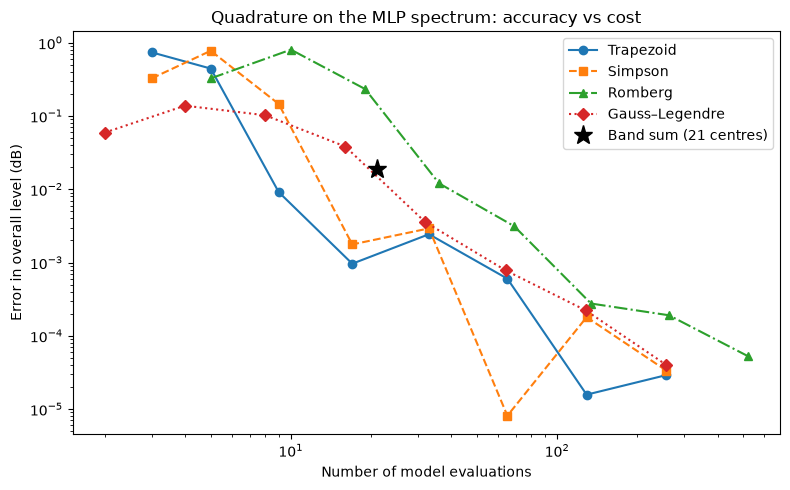

Method,Gauss–Legendre,Romberg,Simpson,Trapezoid
n,,,,
2,5.9e-02,3.3e-01,3.3e-01,7.4e-01
4,1.4e-01,8.0e-01,7.8e-01,4.4e-01
8,1.0e-01,2.3e-01,1.5e-01,9.1e-03
16,3.8e-02,1.2e-02,1.8e-03,9.6e-04
32,3.5e-03,3.1e-03,2.9e-03,2.4e-03
64,7.8e-04,2.8e-04,8.1e-06,6.0e-04
128,2.2e-04,1.9e-04,1.8e-04,1.6e-05
256,4.0e-05,5.3e-05,3.4e-05,2.9e-05


In [12]:
rows = []
for n in [2, 4, 8, 16, 32, 64, 128, 256]:
    for name, method in [("Trapezoid", trapezoid), ("Simpson", simpson),
                         ("Gauss–Legendre", gauss_legendre)]:
        g = CountingIntegrand()
        value = method(g, a, b, n)
        rows.append({"Method": name, "n": n, "Evaluations": g.calls,
                     "Error (dB)": abs(to_db(value) - L_true)})

for levels in range(2, 10):
    g = CountingIntegrand()
    value = romberg(g, a, b, levels)
    rows.append({"Method": "Romberg", "n": 2 ** (levels - 1), "Evaluations": g.calls,
                 "Error (dB)": abs(to_db(value) - L_true)})

quad = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 5))
for name, marker, style in [("Trapezoid", "o", "-"), ("Simpson", "s", "--"),
                            ("Romberg", "^", "-."), ("Gauss–Legendre", "D", ":")]:
    sub = quad[quad["Method"] == name]
    ax.loglog(sub["Evaluations"], sub["Error (dB)"].clip(lower=1e-14),
              marker=marker, linestyle=style, label=name)
ax.loglog([21], [max(abs(L_band - L_true), 1e-14)], "k*", markersize=14, label="Band sum (21 centres)")
ax.set_xlabel("Number of model evaluations")
ax.set_ylabel("Error in overall level (dB)")
ax.set_title("Quadrature on the MLP spectrum: accuracy vs cost")
ax.legend()
plt.tight_layout()
plt.savefig("../results/quadrature_comparison.png", dpi=150)
plt.show()

quad.pivot(index="n", columns="Method", values="Error (dB)").map(lambda v: f"{v:.1e}")

Overall level over 106 set-ups: RMSE 2.35 dB, worst 12.6 dB, 84% within ±3 dB


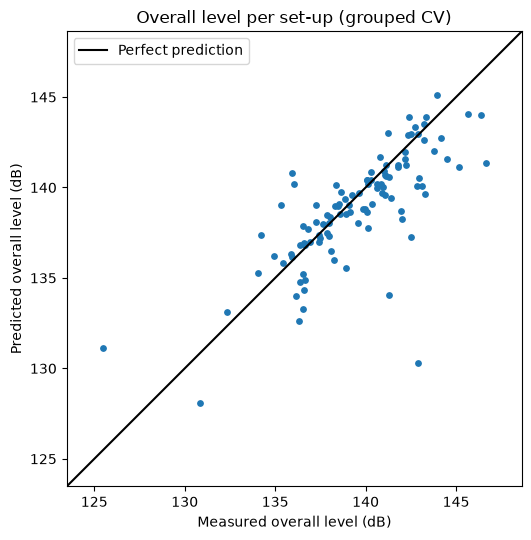

In [13]:
from sklearn.model_selection import GroupKFold
from airfoil.validation import cross_val_predictions, setup_groups

groups = setup_groups(df)
y_oof = cross_val_predictions(clone(final), X_log, y, GroupKFold(5), groups)

rows = []
for g_id in np.unique(groups):
    rows_mask = groups == g_id
    rows.append({"Measured overall (dB)": db_sum(y[rows_mask]),
                 "Predicted overall (dB)": db_sum(y_oof[rows_mask]),
                 "Bands measured": rows_mask.sum()})
overall = pd.DataFrame(rows)
overall["Error (dB)"] = overall["Predicted overall (dB)"] - overall["Measured overall (dB)"]

err = overall["Error (dB)"]
print(f"Overall level over 106 set-ups: RMSE {np.sqrt(np.mean(err**2)):.2f} dB, "
      f"worst {err.abs().max():.1f} dB, {np.mean(err.abs() <= 3) * 100:.0f}% within ±3 dB")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(overall["Measured overall (dB)"], overall["Predicted overall (dB)"], s=15)
lims = [overall.iloc[:, :2].min().min() - 2, overall.iloc[:, :2].max().max() + 2]
ax.plot(lims, lims, "k-", label="Perfect prediction")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_xlabel("Measured overall level (dB)")
ax.set_ylabel("Predicted overall level (dB)")
ax.set_title("Overall level per set-up (grouped CV)")
ax.legend()
plt.tight_layout()
plt.savefig("../results/overall_level_parity.png", dpi=150)
plt.show()

## Quadrature: overall noise level from the model's spectrum

Set-up: c = 0.3048 m, α = 0°, U = 55.5 m/s. The overall level integrates
10^(L/10) over ln(f) between the outer edges of the 200 Hz and 20 kHz bands.

**Reference:** trapezoid with 2¹⁶ intervals gives 136.687717 dB. Doubling
from 2¹⁵ changed it by only 3 × 10⁻¹⁰ dB, so it has converged.

**Band sum:** the usual engineering shortcut (21 band centres, `db_sum`)
gives 136.7067 dB, only 0.019 dB from the reference, more than 100× smaller
than the model's own error.

**Error (dB) vs n** (intervals; points for Gauss):

| n | Trapezoid | Simpson | Romberg | Gauss–Legendre |
|:-:|:-:|:-:|:-:|:-:|
| 2 | 0.74 | 0.33 | 0.33 | 0.059 |
| 8 | 0.0091 | 0.15 | 0.23 | 0.10 |
| 16 | 0.00096 | 0.0018 | 0.012 | 0.038 |
| 64 | 0.0006 | 0.0000081 | 0.00028 | 0.00078 |
| 256 | 0.000029 | 0.000034 | 0.000053 | 0.000040 |

**What I found**
- **The methods don't follow textbook convergence.** Errors are erratic and
  sometimes increase when n doubles. Over the long run all four settle to
  roughly second order (trapezoid: about 60× smaller for 8× more intervals,
  close to the 64× expected for h²). Simpson, Romberg and Gauss don't show
  their usual higher-order advantage.
- **The reason is the ReLU MLP's kinks.** The network is piecewise linear,
  so its spectrum isn't smooth, and higher-order methods rely on smooth
  higher derivatives. With kinks they drop to about second order.
  Simpson's very small error at n = 64 is a lucky cancellation, since it
  rises again at n = 128.
- **Romberg is the least efficient:** my implementation recomputes the
  trapezoid at each level, and Richardson extrapolation assumes a smooth
  error pattern that kinks destroy.
- **Gauss is best with very few points** (0.059 dB with 2 points), but its
  advantage disappears beyond that.
- **In practice the method doesn't matter:** every method is below 0.01 dB
  with about 10–20 evaluations, hundreds of times smaller than the model's
  2.6 dB error. The band sum or the trapezoid rule is the sensible choice.
- **Overall level across all 106 set-ups** (grouped CV): RMSE 2.35 dB, worst
  12.6 dB, 84% within ±3 dB, slightly better than individual bands
  (2.56 dB, 82%) because combining bands averages out some errors. The
  loudest set-ups are under-predicted and the quietest over-predicted,
  the same pull towards the middle seen in Phase 5.

**Lesson:** higher-order quadrature only pays off for smooth integrands.
For a ReLU network's output, simple methods are just as good, and the
integration error is negligible compared with the model error.

## Learning curve and final comparison

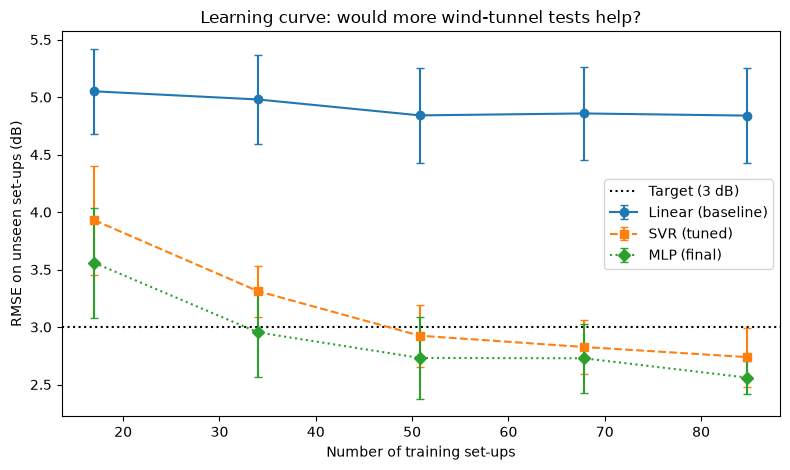

,model,fraction,setups,rmse,std
0,Linear (baseline),0.2,17.0,5.05,0.37
1,Linear (baseline),0.4,34.0,4.98,0.39
2,Linear (baseline),0.6,50.8,4.84,0.41
3,Linear (baseline),0.8,67.8,4.86,0.40
4,Linear (baseline),1.0,84.8,4.84,0.41
5,MLP (final),0.2,17.0,3.56,0.48
6,MLP (final),0.4,34.0,2.95,0.39
7,MLP (final),0.6,50.8,2.73,0.36
8,MLP (final),0.8,67.8,2.73,0.30
9,MLP (final),1.0,84.8,2.56,0.15


In [14]:
from airfoil.validation import regression_metrics

rng = np.random.default_rng(0)
fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
lc_models = {
    "Linear (baseline)": (models["Linear"][0], X_raw),
    "SVR (tuned)": (models["SVR (tuned)"][0], X_log),
    "MLP (final)": (models["MLP (final)"][0], X_log),
}

rows = []
for fold, (train_idx, test_idx) in enumerate(GroupKFold(5).split(X_log, y, groups)):
    train_setups = np.unique(groups[train_idx])
    for frac in fractions:
        repeats = 1 if frac == 1.0 else 2          # 100% is the same set every time
        for rep in range(repeats):
            n_keep = max(2, round(frac * len(train_setups)))
            chosen = rng.choice(train_setups, size=n_keep, replace=False)
            subset = train_idx[np.isin(groups[train_idx], chosen)]
            for name, (model, X) in lc_models.items():
                fitted = clone(model).fit(X[subset], y[subset])
                rmse = regression_metrics(y[test_idx], fitted.predict(X[test_idx]))["rmse"]
                rows.append({"fold": fold, "fraction": frac, "training set-ups": n_keep,
                             "model": name, "rmse": rmse})

lc = pd.DataFrame(rows)
lc_summary = (lc.groupby(["model", "fraction"])
                .agg(setups=("training set-ups", "mean"), rmse=("rmse", "mean"), std=("rmse", "std"))
                .reset_index())

fig, ax = plt.subplots(figsize=(8, 4.8))
for name, marker, style in [("Linear (baseline)", "o", "-"), ("SVR (tuned)", "s", "--"),
                            ("MLP (final)", "D", ":")]:
    sub = lc_summary[lc_summary["model"] == name]
    ax.errorbar(sub["setups"], sub["rmse"], yerr=sub["std"], marker=marker,
                linestyle=style, capsize=3, label=name)
ax.axhline(3.0, linestyle=":", color="black", label="Target (3 dB)")
ax.set_xlabel("Number of training set-ups")
ax.set_ylabel("RMSE on unseen set-ups (dB)")
ax.set_title("Learning curve: would more wind-tunnel tests help?")
ax.legend()
plt.tight_layout()
plt.savefig("../results/learning_curve.png", dpi=150)
plt.show()

lc_summary.round(2)

In [ ]:
base = pd.read_csv("../results/baseline_results.csv").set_index(["Model", "Scheme"])
ml = pd.read_csv("../results/ml_results.csv").set_index(["Model", "Scheme"])
tuned = pd.read_csv("../results/tuning_summary.csv").set_index("Model")
t = timing.set_index("Model")
full_lc = lc_summary[lc_summary["fraction"] == 1.0].set_index("model")["rmse"]
half_lc = lc_summary[lc_summary["fraction"] == 0.4].set_index("model")["rmse"]

final_table = pd.DataFrame({
    "Linear (baseline)": [
        base.loc[("Linear (raw)", "grouped"), "RMSE mean (dB)"],
        base.loc[("Linear (raw)", "leave_one_chord_out"), "RMSE mean (dB)"],
        t.loc["Linear", "Train (s)"], t.loc["Linear", "Per point in batch (µs)"],
        t.loc["Linear", "Saved size (kB)"],
        half_lc["Linear (baseline)"] - full_lc["Linear (baseline)"],
        "High (6 coefficients)", "Yes (linear)"],
    "SVR (tuned)": [
        tuned.loc["SVR (RBF)", "Tuned, nested CV (dB)"],
        ml.loc[("SVR (RBF) (log f, δ*)", "leave_one_chord_out"), "RMSE mean (dB)"],
        t.loc["SVR (tuned)", "Train (s)"], t.loc["SVR (tuned)", "Per point in batch (µs)"],
        t.loc["SVR (tuned)", "Saved size (kB)"],
        half_lc["SVR (tuned)"] - full_lc["SVR (tuned)"],
        "Low (1,076 support vectors)", "Yes (smooth)"],
    "MLP (final)": [
        tuned.loc["MLP", "Tuned, nested CV (dB)"],
        ml.loc[("MLP 64-64 (log f, δ*)", "leave_one_chord_out"), "RMSE mean (dB)"],
        t.loc["MLP (final)", "Train (s)"], t.loc["MLP (final)", "Per point in batch (µs)"],
        t.loc["MLP (final)", "Saved size (kB)"],
        half_lc["MLP (final)"] - full_lc["MLP (final)"],
        "Low (17,409 weights)", "Yes (piecewise linear)"],
}, index=["Grouped CV RMSE (dB)", "Unseen chords RMSE (dB)", "Training time (s)",
          "Prediction per point, batch (µs)", "Saved size (kB)",
          "Gain from 40% → 100% data (dB)", "Interpretability", "Usable derivatives"])
final_table.to_csv("../results/final_comparison.csv")
final_table

,Linear (baseline),SVR (tuned),MLP (final)
Grouped CV RMSE (dB),4.839291,2.807944,2.613321
Unseen chords RMSE (dB),4.880686,3.356902,3.186001
Training time (s),0.001459,0.07673,2.242181
"Prediction per point, batch (µs)",0.156307,53.565782,1.238337
Saved size (kB),1.027344,56.085938,556.00293
Gain from 40% → 100% data (dB),0.140325,0.573271,0.393154
Interpretability,High (6 coefficients),"Low (1,076 support vectors)","Low (17,409 weights)"
Usable derivatives,Yes (linear),Yes (smooth),Yes (piecewise linear)


: 

## Learning curve and final comparison

**Learning curve** (grouped 5-fold CV; training on 20–100% of the training
set-ups, whole set-ups only):

| Training set-ups | Linear | SVR | MLP |
|:-:|:-:|:-:|:-:|
| 17 (20%) | 5.05 | 3.93 | 3.56 |
| 34 (40%) | 4.98 | 3.31 | 2.95 |
| 51 (60%) | 4.84 | 2.92 | 2.73 |
| 85 (100%) | 4.84 | 2.74 | 2.56 |

- **Linear regression flattens out** at about 4.84 dB from 50 set-ups. A
  straight line can't follow the spectral shape, so its limit is the model,
  not the amount of data.
- **The MLP and SVR are still improving at 100%, with diminishing returns**
  (0.39 and 0.57 dB gained from 40% to 100%). The MLP's spread also shrinks
  (± 0.48 → ± 0.15 dB), so more data makes it more consistent too. More
  wind-tunnel set-ups would probably reduce the error further, but only
  modestly.
- **The MLP needs less data:** it reaches my 3 dB target with about 34
  set-ups (40%), while SVR needs about 51 (60%), and it is better than SVR
  at every data size.
- **The most useful new tests** would be small chords at high angles of
  attack, where Phase 5 showed the errors concentrate, rather than more of
  the conditions already tested.

**Final comparison**

| | Linear (baseline) | SVR (tuned) | MLP (final) |
|:--|:-:|:-:|:-:|
| Grouped CV RMSE (dB) | 4.84 | 2.81 | **2.61** |
| Unseen chords RMSE (dB)* | 4.88 | 3.36 | **3.19** |
| Training time (s) | **0.0015** | 0.061 | ___ |
| Prediction per point, batch (µs) | **0.13** | ___ | ___ |
| Saved size (kB) | **1** | 56 | 556 |
| Gain from 40% → 100% data (dB) | 0.14 | 0.57 | 0.39 |
| Interpretability | **High** | Low | Low |
| Usable derivatives | Yes | Yes | Yes (piecewise linear) |

*SVR and MLP unseen-chord results use default settings (Phase 4). Timings
are from my laptop and varied by up to about 2× between runs for the MLP,
so I compare ratios rather than exact times.

**Justification:** the MLP is about 2.2 dB (46%) more accurate than the
linear baseline and meets my 3 dB target, which the baseline doesn't. That
accuracy costs seconds of training instead of milliseconds, a 556 kB file
instead of 1 kB, and interpretability. Those costs are acceptable for a
design tool: training happens once, predictions are fast in a batch, and
the file is small. Compared with SVR, the MLP is slightly more accurate,
needs less data to reach the target, and is much faster per prediction in a
batch, though slower to train. Linear regression remains useful as a
transparent sanity check.